 Perform a descriptive analysis of the dataset to understand population trends

In [2]:
#Import frameworks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Load and Inspect dataset

In [3]:
#Load dataset
df = pd.read_csv("POP.csv")

In [17]:
df.head()

,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ranking,NaN,Economy,(thousands),NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,IND,1,NaN,India,"1,417,173",NaN


In [4]:
#Inspect dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 328 entries, 0 to 327
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       229 non-null    str    
 1   Population 2022  220 non-null    str    
 2   Unnamed: 2       0 non-null      float64
 3   Unnamed: 3       230 non-null    str    
 4   Unnamed: 4       230 non-null    str    
 5   Unnamed: 5       2 non-null      str    
dtypes: float64(1), str(5)
memory usage: 20.9 KB


In [9]:
df.describe()

,Unnamed: 2
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


In [7]:
df.shape

(328, 6)

In [8]:
df.dtypes

Unnamed: 0             str
Population 2022        str
Unnamed: 2         float64
Unnamed: 3             str
Unnamed: 4             str
Unnamed: 5             str
dtype: object

In [24]:
#Check for missing values
df.isnull().sum()

Unnamed: 0          99
Population 2022    108
Unnamed: 2         328
Unnamed: 3          98
Unnamed: 4          98
Unnamed: 5         326
dtype: int64

In [15]:
#Check for duplicates
df.duplicated().sum()

np.int64(95)

Data Wrangling

In [22]:
#Clean the dataset
df_clean = df.iloc[5:, [0,1,3,4]].copy()

In [40]:
#Renaming columns
df_clean.columns = ['country_code', 'ranking', 'country_name', 'population_thousands']

In [41]:
#Drop empty rows
df_clean = df_clean.dropna(subset=['country_name']).copy()

In [57]:
#Format population as numeric
df_clean['population'] = df_clean['population_thousands'].str.replace(',','').astype(float)*1000

In [45]:
#Display the cleaned dataset
df_clean[['ranking', 'country_code', 'country_name', 'population']].head(10)

,ranking,country_code,country_name,population
5,2,CHN,China,1.412175e+09
6,3,USA,United States,3.332880e+08
7,4,IDN,Indonesia,2.755010e+08
8,5,PAK,Pakistan,2.358250e+08
9,6,NGA,Nigeria,2.185410e+08
10,7,BRA,Brazil,2.153130e+08
11,8,BGD,Bangladesh,1.711860e+08
12,9,RUS,Russian Federation,1.435560e+08
13,10,MEX,Mexico,1.275040e+08
14,11,JPN,Japan,1.251250e+08


Dataset given contains population of 2022, hence we cannot filter for year 2000-2020

Exploratory Data Analysis

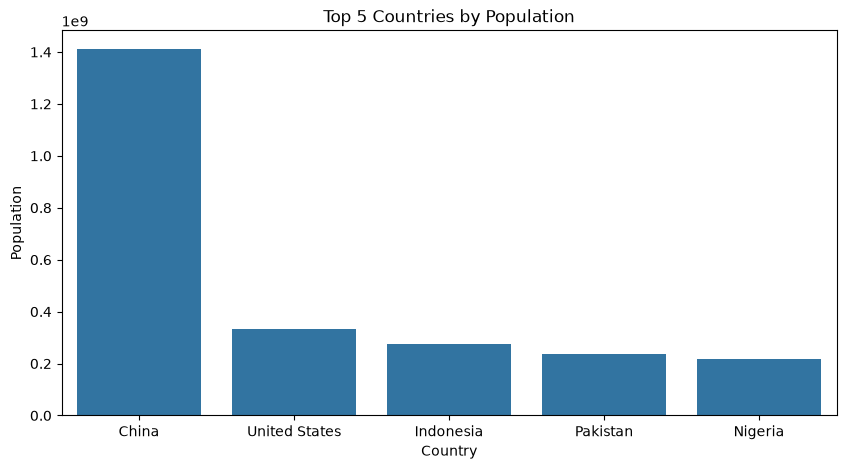

In [49]:
#Plot population graowth trends in top 5 countries
plt.figure(figsize=(10,5))
top = df_clean.head(5)
sns.barplot(x='country_name', y='population', data=top)
plt.title('Top 5 Countries by Population')
plt.xlabel('Country')
plt.ylabel('Population')
plt.show()

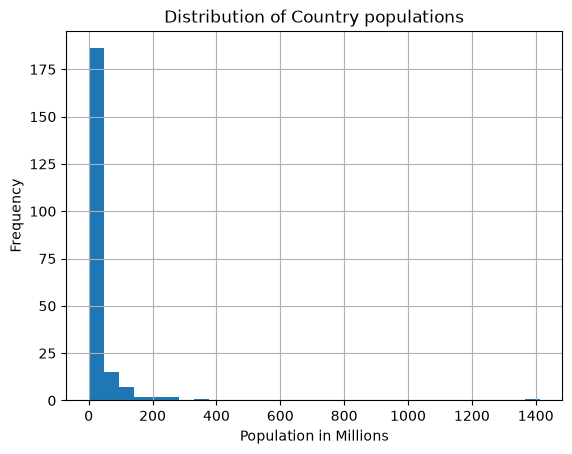

In [58]:
#Histogram of population distribution
df_clean['population_millions'] = df_clean['population']/1e6
df_clean['population_millions'].hist(bins=30)
plt.title('Distribution of Country populations')
plt.xlabel('Population in Millions')
plt.ylabel('Frequency')
plt.show()

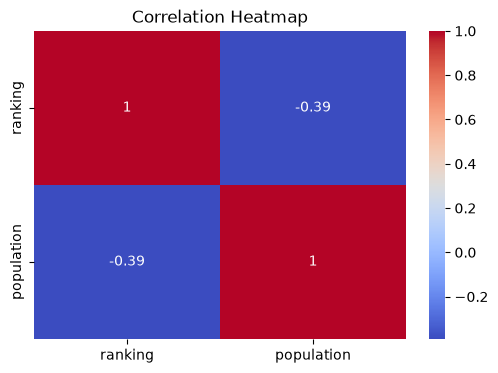

In [61]:
#Generate correlation heatmap for GDP vs Population
#We will use ranking and population for genarting the heatmap since our dataset contains population and ranking as the numerical columns
plt.figure(figsize=(6,4))
numeric_cols = df_clean[['ranking', 'population']]
correlation_matrix = numeric_cols.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()